# JOJA: Analyse exploratoire des données

## Contexte et objectif

Nous disposons des données d'un site de livraison de courses : **~3,4 millions de commandes** passées par **~206 000 clients**, chaque client ayant entre 4 et 100 commandes. Les produits sont regroupés en **rayons** (*aisles*), eux-mêmes regroupés en **départements**.

Objectif : explorer ces données pour en tirer des **insights actionnables**, c'est-à-dire des constats chiffrés qui débouchent sur une décision concrète pouvant améliorer l'activité du e-commerce.

## Les fichiers .csv téléchargés

| Fichier | Une ligne = | Colonnes clés |
|---|---|---|
| `orders` | une commande | `order_id`, `user_id`, `order_number` (rang de la commande du client), `order_dow` (jour, 0 = dimanche), `order_hour_of_day` (heure), `days_since_prior_order` |
| `order_products` | un produit dans une commande | `order_id`, `product_id`, `add_to_cart_order` (position dans le panier), `reordered` (1 = déjà commandé avant) |
| `products` | un produit | `product_id`, `product_name`, `aisle_id`, `department_id` |
| `aisles` | un rayon | `aisle_id`, `aisle` |
| `departments` | un département | `department_id`, `department` |


## Méthodologie

Pour comprendre ces données, nous utilisons la méthode EDA (exploratory data analysis). D'après nos recherches, cette méthode consiste à "transformer un dataset brut en un objet compréhensible. Elle permet de révéler des structures invisibles, d’identifier des biais et d’orienter les choix méthodologiques pour les analyses futures" ([iana-data](https://www.iana-data.org/articles/analyse-exploratoire-des-donnees-eda/#definition)) :

1. **Chargement et typage** (lire les fichiers, choisir des types adaptés au volume)
2. **Contrôle qualité** (dimensions, valeurs manquantes, valeurs aberrantes)
3. **Préparation** (merge/réorganiser les données qui vont ensemble)
4. **Analyse question par question** : problème → mesure → **un** graphique adapté → observation → piste d'action.
5. **Synthèse** 

## Outils et justification des choix

| Paquet | Rôle | Pourquoi ce choix |
|---|---|---|
| **pandas** | manipulation de données tabulaires | structure `DataFrame` ; gère nos volumes (32 M lignes) en mémoire vive |
| **numpy** | calcul numérique vectorisé | opérations sur des tableaux entiers sans boucle Python |
| **matplotlib** | graphiques | bibliothèque de référence pour personnaliser les éléments d'un graphique (axes, titres, légendes) |
| **seaborn** | graphiques statistiques | introduite à partir des questions qui en ont besoin |

## Règle sur les visualisations

Nous n'utilisons pas le même graphique pour des besoins différents :

| Besoin | Graphique retenu |
|---|---|
| **distribution** (répartition d'une variable) | histogramme, boîte à moustaches |
| **comparaison** (classer des catégories) | diagramme en barres |
| **proportion** (part d'un tout) | barres empilées à 100 % |
| **relation** (lien entre deux variables) | nuage de points, carte de chaleur |


# 1. Préparation des données

## 1.1 Chargement et typage

On commence par importer les données .csv, qui sont ensuite lues avec `pd.read_csv("chemin/fichier.csv")`. pd.read renvoie un **DataFrame** :
un tableau avec des colonnes nommées et des lignes numérotées.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.float_format", "{:.2f}".format)

In [2]:
orders      = pd.read_csv("datasets/orders.csv")
products    = pd.read_csv("datasets/products.csv")
aisles      = pd.read_csv("datasets/aisles.csv")
departments = pd.read_csv("datasets/departments.csv")

print("Fichiers chargés")

Fichiers chargés


Etant donnée que ces fichiers sont assez lourds, on essaie de réduire leur taille en précisant le type de chaque colonne avec `dtype=...` pour que le tableau tienne en mémoire sans problème (`int8` = petit nombre, `int32` = grand nombre).


In [3]:

types = {
    "order_id": "int32",
    "product_id": "int32",
    "add_to_cart_order": "int16",
    "reordered": "int8",
}
order_products = pd.read_csv("datasets/order_products.csv", dtype=types)

print("Chargé :", len(order_products), "lignes")

Chargé : 32434489 lignes


Pour terminer, on jette un coup d'oeil aux données :

In [4]:
print("Dimensions :", orders.shape)
orders.info()
display(orders.head())
display(orders.describe())

Dimensions : (3421083, 7)
<class 'pandas.DataFrame'>
RangeIndex: 3421083 entries, 0 to 3421082
Data columns (total 7 columns):
 #   Column                  Dtype  
---  ------                  -----  
 0   order_id                int64  
 1   user_id                 int64  
 2   eval_set                str    
 3   order_number            int64  
 4   order_dow               int64  
 5   order_hour_of_day       int64  
 6   days_since_prior_order  float64
dtypes: float64(1), int64(5), str(1)
memory usage: 198.9 MB


,order_id,user_id,eval_set,order_number,order_dow,order_hour_of_day,days_since_prior_order
0,2539329,1,prior,1,2,8,NaN
1,2398795,1,prior,2,3,7,15.00
2,473747,1,prior,3,3,12,21.00
3,2254736,1,prior,4,4,7,29.00
4,431534,1,prior,5,4,15,28.00


,order_id,user_id,order_number,order_dow,order_hour_of_day,days_since_prior_order
count,3421083.00,3421083.00,3421083.00,3421083.00,3421083.00,3214874.00
mean,1710542.00,102978.21,17.15,2.78,13.45,11.11
std,987581.74,59533.72,17.73,2.05,4.23,9.21
min,1.00,1.00,1.00,0.00,0.00,0.00
25%,855271.50,51394.00,5.00,1.00,10.00,4.00
50%,1710542.00,102689.00,11.00,3.00,13.00,7.00
75%,2565812.50,154385.00,23.00,5.00,16.00,15.00
max,3421083.00,206209.00,100.00,6.00,23.00,30.00


## 1.2 Contrôle qualité

Les fichiers sont chargés. Avant de se lancer dans l'analyse, on prend le temps d'inspecter les données. Pour cela, on se pose trois questions :

1. Les **dimensions** collent-elles avec ce qu'annonce le sujet ?
2. Y a-t-il des **valeurs manquantes**, et si oui, pourquoi ?
3. Y a-t-il des **valeurs aberrantes** ?

On vérifie que les clefs primaires matchent entre elles.


In [5]:
tables = {
    "orders": orders,
    "order_products": order_products,
    "products": products,
    "aisles": aisles,
    "departments": departments,
}

for nom, df in tables.items():
    print(f"{nom:16} {df.shape[0]:>12,} lignes  x  {df.shape[1]} colonnes")

print("\nClients distincts        :", orders["user_id"].nunique())
print("order_id unique (orders) :", orders["order_id"].is_unique)
print("product_id unique        :", products["product_id"].is_unique)


orders              3,421,083 lignes  x  7 colonnes
order_products     32,434,489 lignes  x  4 colonnes
products               49,688 lignes  x  4 colonnes
aisles                    134 lignes  x  2 colonnes
departments                21 lignes  x  2 colonnes

Clients distincts        : 206209


order_id unique (orders) : True
product_id unique        : True


**Ce qu'on lit :**

- Les volumes correspondent au sujet : ~3,4 M de commandes, **206 209 clients**,
  ~50 000 produits. La table `order_products` (~32 M lignes) est bien plus grosse
  que `orders`
- `order_id` est unique dans `orders`, `product_id` est unique dans `products`

En revanche, en listant les colonnes de `orders` (via le `.info()` plus haut), on
tombe sur une colonne **`eval_set`** qui **n'apparaît pas** dans le tableau des
champs du sujet.


In [6]:
orders["eval_set"].value_counts()

eval_set
prior    3214874
train     131209
test       75000
Name: count, dtype: int64

Trois valeurs : `prior` (3,21 M), `train` (0,13 M) et `test` (0,08 M)

Justement, puisqu'on voulait vérifier que les tables se raccordent : est-ce que
**toutes** les commandes de `orders` ont leur détail dans `order_products` ? On
compare les `order_id` et les `product_id` présents de chaque côté.

In [7]:
ids_orders  = set(orders["order_id"])
ids_details = set(order_products["order_id"])
print("Commandes dans orders                      :", len(ids_orders))
print("Commandes avec au moins une ligne de detail :", len(ids_details))
print("  -> dans orders mais sans aucun detail     :", len(ids_orders - ids_details))
print("  -> details sans commande correspondante   :", len(ids_details - ids_orders))

prod_commandes = set(order_products["product_id"])
prod_catalogue = set(products["product_id"])
print("Produits commandes absents du catalogue     :", len(prod_commandes - prod_catalogue))
print("Produits du catalogue jamais commandes      :", len(prod_catalogue - prod_commandes))


Commandes dans orders                      :

 3421083
Commandes avec au moins une ligne de detail : 3214874
  -> dans orders mais sans aucun detail     : 206209
  -> details sans commande correspondante   : 0
Produits commandes absents du catalogue     : 0
Produits du catalogue jamais commandes      : 11


**Deux découvertes.**

1. **206 209 commandes n'ont aucune ligne de détail** dans `order_products`.
   L'inverse est à 0 (aucun détail orphelin) : `order_products` est donc un
   **sous-ensemble** propre de `orders`.
2. **11 produits du catalogue n'ont jamais été commandés** (49 688 référencés,
   49 677 vendus). 

On isole les 206 209 commandes sans détail et on les décrit pour comprendre.


In [8]:
manquantes = orders[~orders["order_id"].isin(ids_details)]

print(manquantes["eval_set"].value_counts(), "\n")
print("Clients concernes :", manquantes["user_id"].nunique(), "/", orders["user_id"].nunique())

dernier_num = manquantes.groupby("user_id")["order_number"].transform("max")
print("Est-ce toujours la derniere commande du client ?",
      (manquantes["order_number"] == dernier_num).all())


eval_set
train    131209
test      75000
Name: count, dtype: int64 

Clients concernes : 206209 / 206209
Est-ce toujours la derniere commande du client ? True


Le motif est net :

- ces commandes sont **toutes** en `eval_set` `train` ou `test`
  (131 209 + 75 000 = 206 209) ;
- il y en a **exactement une par client** ;
- c'est **toujours la dernière commande** du client (son `order_number` maximal).

Cela veut dire qu'on a retiré à chaque client sa **dernière commande** et on en a masqué
le contenu. 

### Valeurs manquantes

`.isna()` renvoie un tableau de booléens (`True` = case vide) ; `.sum()` les compte
colonne par colonne. On boucle sur les cinq tables et on n'affiche que les colonnes
qui ont au moins une valeur manquante.


In [9]:
for nom, df in tables.items():
    manquants = df.isna().sum()
    manquants = manquants[manquants > 0]
    if len(manquants):
        print(f"{nom} :")
        print(manquants.to_string(), "\n")
    else:
        print(f"{nom} : aucune valeur manquante\n")


orders :
days_since_prior_order    206209 



order_products : aucune valeur manquante

products : aucune valeur manquante

aisles : aucune valeur manquante

departments : aucune valeur manquante



Une seule colonne concernée dans tout le jeu de données :
**`days_since_prior_order`**, avec 206 209 valeurs manquantes.
L'explication logique : c'est la **première commande** de chaque client. Il n'y a
pas de commande précédente, donc « nombre de jours depuis la commande précédente »
n'a aucune valeur possible.


In [10]:
sans_delai = orders["days_since_prior_order"].isna()
print("Valeurs manquantes         :", sans_delai.sum())
print("Toutes a la 1re commande ? :",
      (orders.loc[sans_delai, "order_number"] == 1).all())


Valeurs manquantes         : 206209


Toutes a la 1re commande ? : True


Confirmé : les 206 209 lignes sont toutes à `order_number == 1`.

On garde ces données car les remplacer par `0` serait faux : ça
voudrait dire « commande passée le même jour que la précédente ». 


### Valeurs aberrantes

Pour chaque colonne, on regarde le minimum et le maximum (ou la liste des valeurs
quand il y en a peu) et on se demande si ça correspond au sujet : `order_dow` de 0 à 6, `order_hour_of_day` de 0 à 23,
`reordered` valant 0 ou 1, de 4 à 100 commandes par client.


In [11]:
print("order_dow          :", sorted(orders["order_dow"].unique().tolist()))
print("order_hour_of_day  :", orders["order_hour_of_day"].min(), "->", orders["order_hour_of_day"].max())
print("order_number       :", orders["order_number"].min(), "->", orders["order_number"].max())
print("days_since_prior   :", orders["days_since_prior_order"].min(), "->", orders["days_since_prior_order"].max())
print("reordered          :", sorted(order_products["reordered"].unique().tolist()))
print("add_to_cart_order  :", order_products["add_to_cart_order"].min(), "->", order_products["add_to_cart_order"].max())

commandes_par_client = orders.groupby("user_id")["order_id"].count()
print("commandes par client :", commandes_par_client.min(), "->", commandes_par_client.max())


order_dow          : [0, 1, 2, 3, 4, 5, 6]
order_hour_of_day  : 0 -> 23
order_number       : 1 -> 100
days_since_prior   : 0.0 -> 30.0


reordered          : [0, 1]
add_to_cart_order  : 1 -> 145
commandes par client : 4 -> 100


**Ce qu'on lit :**

- `order_dow` (0-6), `order_hour_of_day` (0-23), `reordered` (0/1),
  `add_to_cart_order` qui démarre à 1 : tout est conforme.
- `commandes par client` : de **4 à 100**, exactement les bornes annoncées par le
  sujet.
- `order_number` s'arrête pile à **100** et `days_since_prior_order` pile à **30**.
- Un panier est monté jusqu'à **145 articles** (`add_to_cart_order` max) : gros,
  mais pas absurde pour des courses.

**Bilan du contrôle qualité :** aucune valeur à corriger, aucune ligne à supprimer.

## 1.3 Préparation

Deux ajustements avant de passer à l'analyse.

### a) Choisir le périmètre d'analyse

On l'a découvert en 1.2 : `order_products` ne contient le détail que des commandes
`prior`. Les 206 209 commandes `train` + `test` (la dernière de chaque client) sont
dans `orders` mais **sans aucun produit**.

Si on analyse le **contenu** des paniers, ces commandes ne servent à rien (elles
sont vides). Si on analyse seulement `orders` (heures, jours...), on pourrait les
garder, mais on mélangerait alors deux périmètres différents selon les questions.
Pour rester cohérent, on se restreint au
périmètre `prior`.


In [12]:
commandes = orders[orders["eval_set"] == "prior"].copy()
print("Commandes retenues pour l'analyse :", f"{len(commandes):,}")

hist = commandes.groupby("user_id")["order_id"].count()
print("Historique par client (prior) : de", hist.min(), "a", hist.max(), "commandes")


Commandes retenues pour l'analyse : 3,214,874
Historique par client (prior) : de 3 a 99 commandes


En retirant la dernière commande de chaque client, l'historique descend à un minimum
de **3 commandes** pour certains clients (au lieu de 4).

### b) Une table produits complète

Plusieurs questions auront besoin du **rayon** (`aisle`) et du **département**
(`department`) de chaque produit. Plutôt que de refaire la jointure à chaque fois,
on construit une fois pour toutes une table `produits` enrichie, en rattachant
`aisles` et `departments` par leur identifiant (`merge` en chaîne).


In [13]:
produits = (
    products
    .merge(aisles, on="aisle_id")
    .merge(departments, on="department_id")
)
produits.head()


,product_id,product_name,aisle_id,department_id,aisle,department
0,1,Chocolate Sandwich Cookies,61,19,cookies cakes,snacks
1,2,All-Seasons Salt,104,13,spices seasonings,pantry
2,3,Robust Golden Unsweetened Oolong Tea,94,7,tea,beverages
3,4,Smart Ones Classic Favorites Mini Rigatoni Wit...,38,1,frozen meals,frozen
4,5,Green Chile Anytime Sauce,5,13,marinades meat preparation,pantry


`produits` porte maintenant, à côté de chaque `product_id` : le nom du produit,
celui de son rayon et celui de son département.

À partir d'ici, on travaille avec :

- **`commandes`** : les ~3,2 M commandes `prior` ;
- **`order_products`** : leur détail (un produit par ligne) ;
- **`produits`** : le référentiel produit enrichi.


---
# Analyse des performances du e-commerce

## *Question 1 : Quels sont les produits les plus vendus ?*

**Type de question :** on veut **classer** des catégories (les produits) du plus vendu au moins vendu. Selon les règles de visualisation, il s'agit d'une une **comparaison**, donc on utilise un graphique en **barres**. Comme les noms de produits sont longs et nombreux, on prend le **top 15** en **barres horizontales**.

« Le plus vendu » = le produit qui apparaît dans le plus grand nombre de lignes de `order_products`.

Sachant qu'une une ligne de `order_products` = un produit acheté dans une commande, on compte les lignes par `product_id`.

In [14]:

ventes_par_produit = order_products.groupby("product_id").size()
ventes_par_produit.head()

product_id
1    1852
2      90
3     277
4     329
5      15
dtype: int64

`.size()` renvoie une **Series** : index = `product_id`, valeur = nombre de ventes.
On veut les plus gros :

- `.sort_values(ascending=False)` : de la plus grande valeur à la plus petite
- `.head(15)` : on garde les 15 premières


In [15]:
top15 = ventes_par_produit.sort_values(ascending=False).head(15)
top15


product_id
24852    472565
13176    379450
21137    264683
21903    241921
47209    213584
47766    176815
47626    152657
16797    142951
26209    140627
27845    137905
27966    137057
22935    113426
24964    109778
45007    104823
39275    100060
dtype: int64

On a des `product_id` (des numéros), pas des noms. Deux étapes :

- `.reset_index(name="ventes")` : transforme la Series en **tableau** à 2 colonnes
  (`product_id`, `ventes`).
- `.merge(products[["product_id", "product_name"]], on="product_id")` : rapproche
  de `products` pour récupérer `product_name` à partir du `product_id`.

In [16]:
top15_noms = (
    top15
    .reset_index(name="ventes")                         
    .merge(products[["product_id", "product_name"]], on="product_id")
)
top15_noms


,product_id,ventes,product_name
0,24852,472565,Banana
1,13176,379450,Bag of Organic Bananas
2,21137,264683,Organic Strawberries
3,21903,241921,Organic Baby Spinach
4,47209,213584,Organic Hass Avocado
5,47766,176815,Organic Avocado
6,47626,152657,Large Lemon
7,16797,142951,Strawberries
8,26209,140627,Limes
9,27845,137905,Organic Whole Milk


**Le graphique.** `plt.barh(noms, valeurs)` = barres **horizontales** (pratique
quand les libellés sont longs). Pour que le produit n°1 apparaisse tout en haut, on trie le tableau en ordre **croissant**.


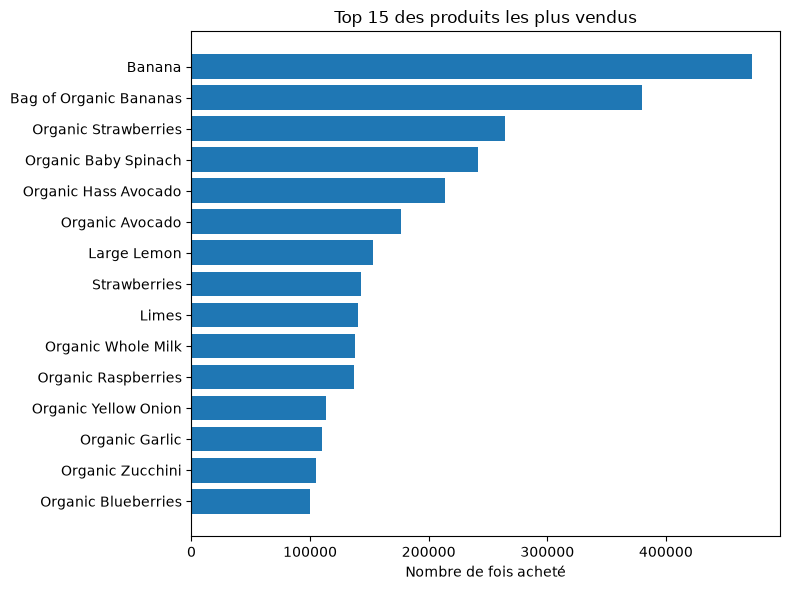

In [17]:
graph = top15_noms.sort_values("ventes") 

plt.figure(figsize=(8, 6))
plt.barh(graph["product_name"], graph["ventes"])
plt.xlabel("Nombre de fois acheté")
plt.title("Top 15 des produits les plus vendus")
plt.tight_layout()
plt.show()


**Observations :**

- Le classement est dominé par des **fruits et légumes frais**, très souvent bio :
  bananes, fraises, épinards, avocats, myrtilles... (mention *Organic* récurrente).
- Le produit n°1 (*Banana*) pèse à lui seul ~1,46 % de toutes les lignes vendues du site
- Ce sont des produits **peu chers achetés très fréquemment** (la fréquence d'achat)

**Piste business :**

Veiller au réapprovisionnement ininterrompu de ces 15 produits et les mettre en tête de parcours ou dans les suggestions par défaut pour accélérer le remplissage du panier.

## *Question 2 : Quel est le ratio de commandes bio vs non-bio ?*

**Type de question :** on veut une **part d'un tout** (les commandes qui contiennent
du bio, rapportées à l'ensemble des commandes). D'après les règles de visualisation,
une proportion se montre avec une **barre empilée à 100 %**.

**« Commande bio »** = une commande qui contient **au moins un** produit bio. Le
seul indice pour repérer un produit bio est son **nom** : on considère bio tout
produit dont le `product_name` contient « organic ». C'est une approximation (un
produit bio mal nommé passera pour non-bio), mais c'est la seule information
disponible.


In [18]:
produits["bio"] = produits["product_name"].str.contains("organic", case=False, na=False)

nb_bio = produits["bio"].sum()
print(f"Produits bio : {nb_bio:,} / {len(produits):,} ({nb_bio / len(produits):.1%} du catalogue)")
produits.loc[produits["bio"], ["product_name", "aisle", "department"]].head()


Produits bio : 5,036 / 49,688 (10.1% du catalogue)


,product_name,aisle,department
22,Organic Turkey Burgers,packaged poultry,meat seafood
32,Organic Spaghetti Style Pasta,dry pasta,dry goods pasta
40,Organic Sourdough Einkorn Crackers Rosemary,crackers,snacks
42,Organic Clementines,packaged vegetables fruits,produce
46,Onion Flavor Organic Roasted Seaweed Snack,asian foods,international


`str.contains("organic", case=False)` teste, pour chaque nom de produit, la présence
du mot « organic » sans tenir compte de la casse ; `na=False` traite un nom manquant
comme « pas bio ».

Environ **10 % du catalogue** est bio. On reporte maintenant cette étiquette sur
chaque ligne de `order_products` (une ligne = un produit dans une commande). Plutôt
qu'un `merge` sur 32 M de lignes, on construit l'ensemble des `product_id` bio et on
teste l'appartenance avec `.isin()`.


In [19]:
bio_ids = set(produits.loc[produits["bio"], "product_id"])
order_products["bio"] = order_products["product_id"].isin(bio_ids)

part_lignes_bio = order_products["bio"].mean()
print(f"Lignes produits bio : {part_lignes_bio:.1%}")

Lignes produits bio : 31.6%


**31,6 %** des lignes achetées sont des produits bio : trois fois plus que la part
du bio dans le catalogue (10 %). Les produits bio se vendent donc proportionnellement
bien mieux que les autres.

On passe au niveau **commande**. Une commande est « bio » si **au moins un** de ses
produits l'est. `groupby("order_id")["bio"].agg(["any", "all"])` calcule en un seul
passage, pour chaque commande : `any` = contient-elle au moins un produit bio,
`all` = sont-ils **tous** bio.


In [20]:
agg = order_products.groupby("order_id")["bio"].agg(["any", "all"])

part_commandes_bio     = agg["any"].mean()
part_commandes_100_bio = agg["all"].mean()
print(f"Commandes avec au moins un produit bio : {part_commandes_bio:.1%}")
print(f"Commandes sans aucun produit bio       : {1 - part_commandes_bio:.1%}")
print(f"Commandes 100 % bio                    : {part_commandes_100_bio:.1%}")

Commandes avec au moins un produit bio : 73.6%
Commandes sans aucun produit bio       : 26.4%
Commandes 100 % bio                    : 2.5%


**73,6 % des commandes** contiennent au moins un produit bio, contre 26,4 % sans
aucun. Le bio n'est pas un segment de niche sur ce site : la majorité des paniers
sont concernés.

On visualise les deux niveaux de lecture (commande / ligne produit) l'un sous
l'autre, chacun en barre empilée à 100 %.


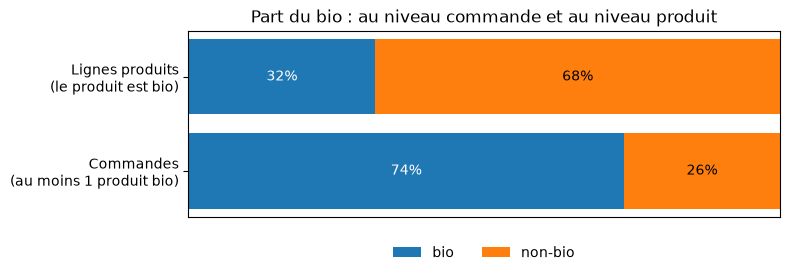

In [21]:
niveaux      = ["Commandes\n(au moins 1 produit bio)", "Lignes produits\n(le produit est bio)"]
part_bio     = [part_commandes_bio, part_lignes_bio]
part_non_bio = [1 - p for p in part_bio]

plt.figure(figsize=(8, 3))
plt.barh(niveaux, part_bio, label="bio")
plt.barh(niveaux, part_non_bio, left=part_bio, label="non-bio")

for i, p in enumerate(part_bio):
    plt.text(p / 2,           i, f"{p:.0%}",     va="center", ha="center", color="white")
    plt.text(p + (1 - p) / 2, i, f"{1 - p:.0%}", va="center", ha="center")

plt.xlim(0, 1)
plt.xticks([])
plt.title("Part du bio : au niveau commande et au niveau produit")
plt.legend(loc="lower center", bbox_to_anchor=(0.5, -0.3), ncol=2, frameon=False)
plt.tight_layout()
plt.show()

**Observations :**

- **73,6 % des commandes** contiennent du bio, mais seulement **31,6 % des lignes
  produits** le sont : dans une commande « bio » typique, le bio cohabite avec une
  majorité de produits non-bio.
- Le bio est **sur-représenté dans les ventes** par rapport à l'offre : 10 % du
  catalogue, 32 % des achats. Ce sont surtout les gros volumes du top 15 (bananes,
  épinards, fraises… en version bio) qui tirent ce chiffre.
- Les commandes **100 % bio** sont rares (~2,5 %) : le bio est un complément de
  panier.

**Piste business :**

Le bio est un réflexe d'achat de masse, pas une niche. Sur les 26 % de commandes
sans aucun produit bio, proposer l'équivalent bio d'un produit déjà au panier au
moment de l'ajout pour convertir ces paniers.


## *Question 3 : Quel est le taux de réachat, au global et par département ?*

**Mesure.** La colonne `reordered` vaut 1 si le client avait déjà commandé ce
produit auparavant, 0 sinon. Le taux de réachat d'un ensemble de lignes est la
moyenne de `reordered` sur ces lignes.

**Visualisation.** On compare des catégories (les départements) sur un même
indicateur : c'est une comparaison, donc un diagramme en barres. Le taux global sert
de repère.


In [22]:
print(f"Taux de reachat global : {order_products['reordered'].mean():.1%}")


Taux de reachat global : 59.0%


59 % des produits achetés avaient déjà été commandés par le client. On décompose par
département : on rattache chaque ligne à son `department_id` via `produits`, puis on
calcule la moyenne de `reordered` par département. On garde aussi le nombre de lignes
pour situer le poids de chaque département.


In [23]:
dept_par_produit = produits.set_index("product_id")["department_id"]
order_products["department_id"] = order_products["product_id"].map(dept_par_produit).astype("int16")

reachat_dept = (
    order_products.groupby("department_id")["reordered"].agg(taux="mean", lignes="size")
    .join(departments.set_index("department_id")["department"])
    .sort_values("taux")
)
reachat_dept


,taux,lignes,department
department_id,,,
11,0.32,447123,personal care
13,0.35,1875577,pantry
6,0.37,269253,international
21,0.40,69145,missing
17,0.40,738666,household
2,0.41,36291,other
15,0.46,1068058,canned goods
9,0.46,866627,dry goods pasta
1,0.54,2236432,frozen


On trace les départements du taux le plus faible au plus fort, avec une ligne
verticale au taux global.


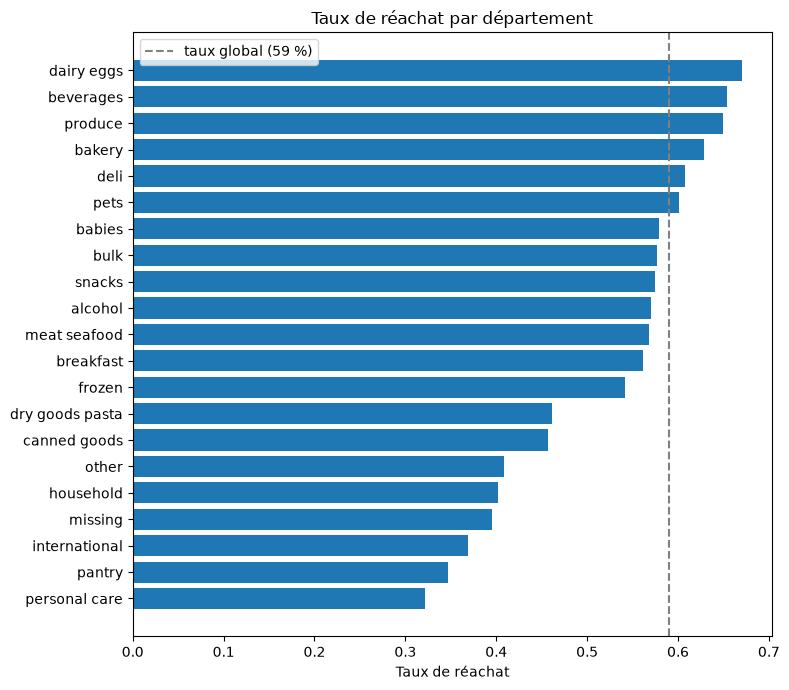

In [24]:
plt.figure(figsize=(8, 7))
plt.barh(reachat_dept["department"], reachat_dept["taux"])
plt.axvline(order_products["reordered"].mean(), color="grey", linestyle="--",
            label="taux global (59 %)")
plt.xlabel("Taux de réachat")
plt.title("Taux de réachat par département")
plt.legend()
plt.tight_layout()
plt.show()


**Observations :**

- Le taux de réachat va de **32 % (personal care)** à **67 % (dairy eggs)**.
- Au-dessus de la moyenne : des consommables du quotidien (dairy eggs, beverages,
  produce, bakery, deli), qui s'épuisent vite et se rachètent.
- En dessous : des achats ponctuels ou de stock (personal care, pantry, household,
  international, canned goods).
- Les deux plus gros départements en volume (produce 9,5 M lignes, dairy eggs
  5,4 M) sont aussi parmi les plus fidélisants : le cœur du chiffre d'affaires est
  récurrent.

**Piste business :**

Cibler les départements à fort volume mais faible réachat (pantry, canned goods,
frozen) avec des rappels de réassort ou des abonnements : produits que le client
rachètera mais oublie. Sur les départements à fort réachat, la priorité est la
disponibilité, pas la promotion.
